In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import rosel.io
import rosel.computation
import rosel.shiroma

In [3]:
in_path = rosel.io.normpath("/home/morea/SAOCOM/")
slc_path = f"{in_path}/INPUT_DATA/slcs.zarr"
acquisition_date = "2023-12-12"
wdir_path = f"{in_path}/WDIR_DATA/{acquisition_date}"
selection_path = f"{wdir_path}/selection"
rtc_ap_path = f"{wdir_path}/rtc_ap"

result_folder = "/home/morea/RESULTS"

In [4]:
slc = rosel.io.read(slc_path).orig[acquisition_date].measurements.slc.squeeze()
selection = rosel.io.read(selection_path)
A = rosel.io.read(rtc_ap_path, mask_and_scale=False).v

In [5]:
slc

<xarray.DataArray 'slc' (azimuth_time: 24897, slant_range_time: 7835)> Size: 2GB
dask.array<getitem, shape=(24897, 7835), dtype=complex64, chunksize=(1024, 1024), chunktype=numpy.ndarray>
Coordinates:
    acquisition_date  <U26 104B '2023-12-12T04:51:48.236453'
    azimuth_m         (azimuth_time) float64 199kB dask.array<chunksize=(1024,), meta=np.ndarray>
  * azimuth_time      (azimuth_time) datetime64[ns] 199kB 2023-12-12T04:51:48...
    slant_range_m     (slant_range_time) float64 63kB dask.array<chunksize=(1024,), meta=np.ndarray>
  * slant_range_time  (slant_range_time) float64 63kB 0.004938 ... 0.005199
Attributes:
    CollectionInfo:   {'Classification': 'UNCLASSIFIED', 'CollectType': 'MONO...
    GeoData:          {'EarthModel': 'WGS_84', 'ImageCorners': [{'Lat': 40.39...
    Grid:             {'Col': {'DeltaK1': -0.08297284776039648, 'DeltaK2': 0....
    ImageCreation:    {'Application': 'SSP SSPV05.0703DB01.6000', 'DateTime':...
    ImageData:        {'FirstCol': 0, 'FirstRow': 0, 'FullImage': {'NumCols':...
    ImageFormation:   {'AzAutofocus': 'NO', 'ImageBeamComp': 'SV', 'ImageForm...
    Position:         {'ARPPoly': {'X': {'Coefs': [5315807.461753006, -4362.7...
    RMA:              {'INCA': {'DRateSFPoly': {'Coefs': [[0.903459367550644]...
    RadarCollection:  {'RcvChannels': [{'TxRcvPolarization': 'V:H', 'index': ...
    SCPCOA:           {'ARPAcc': {'X': -6.484280148509322, 'Y': -0.4198957725...
    Timeline:         {'CollectDuration': 13.407108, 'CollectStart': '2023-12...

In [6]:
A

<xarray.DataArray 'v' (azimuth_time: 24897, slant_range_time: 7835)> Size: 780MB
dask.array<open_dataset-v, shape=(24897, 7835), dtype=float32, chunksize=(1024, 1024), chunktype=numpy.ndarray>
Dimensions without coordinates: azimuth_time, slant_range_time
Attributes:
    _FillValue:  0.0

## Full Resolution

In [7]:
c_gamma = rosel.shiroma.flatten_radar_image(slc, A, data_path=f"{result_folder}/flattened_slc", read=True)

2025-02-25 16:45:42 [warning  ] No global client found a new one will be created
2025-02-25 16:45:42 [debug    ] <Cluster info: type=LOCAL, n_jobs=22, job_memory=2181376828>
2025-02-25 16:45:44 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-25 16:45:44 [debug    ] Number of blocks to be processed: 200


2025-02-25 16:45:46,800 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:43449' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'execute-131a48e5-9081-4617-963d-eca5817e72a1', 'execute-28d0f4cb-2156-4287-8d59-8e5464651833', 'execute-65af3026-d632-45d6-88a4-fce0dfa2a487', 'execute-4635ba51-606c-4bcf-96f7-58e9d91eb98a', 'execute-bb48725e-852e-4bc9-a8cb-2c29945f4da3', 'execute-dc110cb2-7115-4dad-9940-0a84ebb6dcac', 'execute-990d5a36-bdcb-4c9e-ae0b-7c9ffda05ffd', 'execute-eb7dbf07-8ee0-478a-b24c-372714b65eba'} (stimulus_id='handle-worker-cleanup-1740498346.8002517')
2025-02-25 16:45:46,802 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:45983' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'execute-ca3d9c96-5b02-4c62-ab9c-139a20023a2f', 'execute-b6fcf099-975f-43a3-a255-f6981289cb61', 'execute-0da59602-d49d-4658-b20e-4006e1172424', 'execute-1f3fc22d-8660-4ad1-ac13-b3

In [8]:
flattened_intensity = (np.abs(c_gamma) ** 2).to_dataset(name="v")

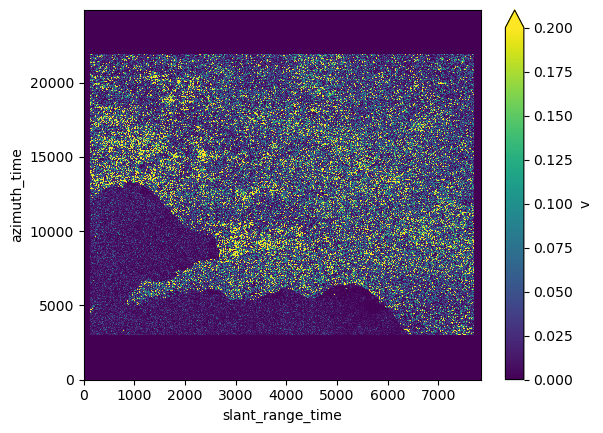

In [9]:
flattened_intensity.v.plot(vmin=0, vmax=0.2)

In [10]:
rosel.io.write(flattened_intensity, f"{result_folder}/flattened_intensity")

<xarray.Dataset> Size: 780MB
Dimensions:  (azimuth_time: 24897, slant_range_time: 7835)
Dimensions without coordinates: azimuth_time, slant_range_time
Data variables:
    v        (azimuth_time, slant_range_time) float32 780MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
Attributes:
    obj_type:    xr.Dataset
    store_path:  /home/morea/RESULTS/flattened_intensity

In [11]:
g = rosel.shiroma.map_geo_ap(
    c_path=f"{result_folder}/flattened_intensity",
    simulation=selection,
    data_path_shiroma=wdir_path,
    data_path_geo_ap=f"{result_folder}/geo_ap",
    read=True,
    enable_dask=True,
)

2025-02-25 16:47:02 [warning  ] No global client found a new one will be created
2025-02-25 16:47:02 [debug    ] <Cluster info: type=LOCAL, n_jobs=22, job_memory=2181376828>
2025-02-25 16:47:03 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-25 16:47:03 [debug    ] Number of blocks to be processed: 5184


2025-02-25 16:48:01,347 - distributed.scheduler - ERROR - Removing worker 'tcp://127.0.0.1:35049' caused the cluster to lose scattered data, which can't be recovered: {'ndarray-9468d45743a5b6c7855d9a47ac16f33b', 'str-99dc503f072bdfe7e690e2dde33903ca', 'str-a5dfb4539d9cbc6706d41a7abcfeed2a', 'str-139135f1edcf93b5b5d614a684a56ce2', 'Dataset-19b2af51581119e13821693e69aaae33', 'int-57f90bedeea3ef51aa1e912ae32f0ae1', 'int-5d5c9ca0dbfe566bf85b8130f464576c'} (stimulus_id='handle-worker-cleanup-1740498481.346996')


In [12]:
g

<xarray.DataArray 'v' (y: 10248, x: 8139)> Size: 667MB
dask.array<open_dataset-v, shape=(10248, 8139), dtype=complex64, chunksize=(128, 128), chunktype=numpy.ndarray>
Coordinates:
  * x        (x) float64 65kB 4.225e+05 4.225e+05 ... 5.039e+05 5.039e+05
  * y        (y) float64 82kB 4.574e+06 4.574e+06 ... 4.471e+06 4.471e+06
Attributes:
    _FillValue:  0j

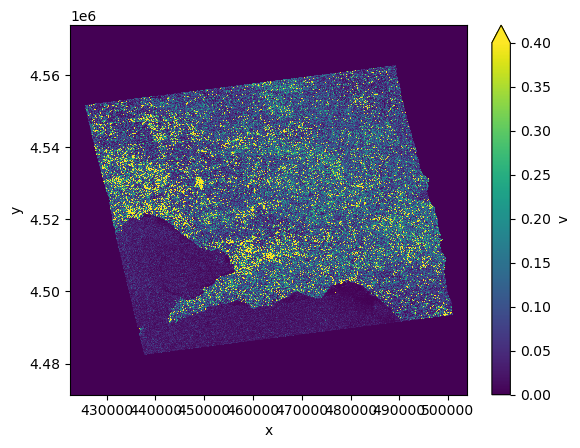

In [13]:
np.real(g).plot(vmin=0, vmax=0.4)

## Multilooked image

In [14]:
multilook = {"azimuth_time": 3, "slant_range_time": 5}

In [15]:
c = np.abs(slc) ** 2

In [16]:
# generating multilooked amplitude
c_ml = (
    c.coarsen(azimuth_time=multilook["azimuth_time"], slant_range_time=multilook["slant_range_time"], boundary="pad")
    .mean()
    .chunk(azimuth_time=300, slant_range_time=300)
)
c_ml = np.sqrt(c_ml)

In [17]:
c_ml

<xarray.DataArray 'slc' (azimuth_time: 8299, slant_range_time: 1567)> Size: 52MB
dask.array<sqrt, shape=(8299, 1567), dtype=float32, chunksize=(300, 300), chunktype=numpy.ndarray>
Coordinates:
    acquisition_date  <U26 104B '2023-12-12T04:51:48.236453'
    azimuth_m         (azimuth_time) float64 66kB dask.array<chunksize=(300,), meta=np.ndarray>
  * azimuth_time      (azimuth_time) datetime64[ns] 66kB 2023-12-12T04:51:48....
    slant_range_m     (slant_range_time) float64 13kB dask.array<chunksize=(300,), meta=np.ndarray>
  * slant_range_time  (slant_range_time) float64 13kB 0.004938 ... 0.005199

In [18]:
c_gamma_ml = rosel.shiroma.flatten_radar_image(
    c_ml, A, multilook=multilook, data_path=f"{result_folder}/flattened_amplitude_ml", read=True
)

2025-02-25 16:48:38 [warning  ] No global client found a new one will be created
2025-02-25 16:48:38 [debug    ] <Cluster info: type=LOCAL, n_jobs=22, job_memory=2181376828>
2025-02-25 16:48:40 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-25 16:48:40 [debug    ] Number of blocks to be processed: 168


2025-02-25 16:48:45,334 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:43503' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'execute-df99f636-1f92-40e1-8b2b-5bd68756a3fa', 'execute-232a63ef-44fc-485a-ae99-ffb679f1c298', 'execute-47fefa60-07b5-4f74-97ae-39122b086a97', 'execute-0520d9e7-31e0-4b3f-882f-9a40e162a8b2', 'execute-c184b9fa-e0a3-4235-b83d-1839c483c24c', 'execute-761300ff-4c9c-41c3-a816-2def23be95b4', 'execute-9225e4cc-5908-4767-88e6-8f7159a51bf1', 'execute-b28ca22c-bf54-4b4d-b85d-059829016e0f'} (stimulus_id='handle-worker-cleanup-1740498525.33442')
2025-02-25 16:48:45,338 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:36747' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'execute-18d83eaa-9996-46c6-b816-f481f3117d97', 'execute-53e58359-14e4-49dc-91d7-00e99fd3c529', 'execute-e2c054da-0863-41e6-a943-c13028f7f6bc', 'execute-c45231cb-6ff8-4775-8e58-9030

In [19]:
flattened_intensity_ml = (np.abs(c_gamma_ml) ** 2).to_dataset(name="v")

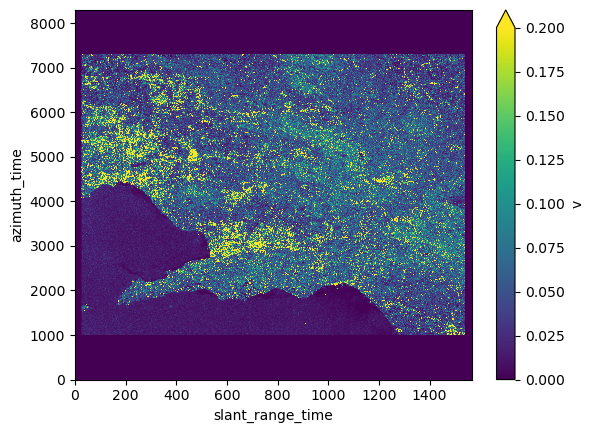

In [20]:
flattened_intensity_ml.v.plot(vmin=0, vmax=0.2)

In [21]:
rosel.io.write(flattened_intensity_ml, f"{result_folder}/flattened_intensity_ml")

<xarray.Dataset> Size: 52MB
Dimensions:  (azimuth_time: 8299, slant_range_time: 1567)
Dimensions without coordinates: azimuth_time, slant_range_time
Data variables:
    v        (azimuth_time, slant_range_time) float32 52MB dask.array<chunksize=(300, 300), meta=np.ndarray>
Attributes:
    obj_type:    xr.Dataset
    store_path:  /home/morea/RESULTS/flattened_intensity_ml

In [22]:
g_ml = rosel.shiroma.map_geo_ap(
    c_path=f"{result_folder}/flattened_intensity_ml",
    simulation=selection,
    data_path_shiroma=wdir_path,
    data_path_geo_ap=f"{result_folder}/geo_ap_ml",
    multilook=multilook,
    read=True,
    enable_dask=True,
)

2025-02-25 16:48:51 [warning  ] No global client found a new one will be created
2025-02-25 16:48:51 [debug    ] <Cluster info: type=LOCAL, n_jobs=22, job_memory=2181376828>
2025-02-25 16:48:52 [debug    ] Selected scatter strategy: once-and-for-all
2025-02-25 16:48:52 [debug    ] Number of blocks to be processed: 5184


2025-02-25 16:49:51,096 - distributed.scheduler - ERROR - Removing worker 'tcp://127.0.0.1:37217' caused the cluster to lose scattered data, which can't be recovered: {'ndarray-9468d45743a5b6c7855d9a47ac16f33b', 'str-d45367979458fcdf9e6463acc34b8d21', 'str-139135f1edcf93b5b5d614a684a56ce2', 'Dataset-19b2af51581119e13821693e69aaae33', 'str-c3d88623a01a1ae14a2944fe38b8b90e', 'int-57f90bedeea3ef51aa1e912ae32f0ae1', 'int-5d5c9ca0dbfe566bf85b8130f464576c'} (stimulus_id='handle-worker-cleanup-1740498591.0959716')


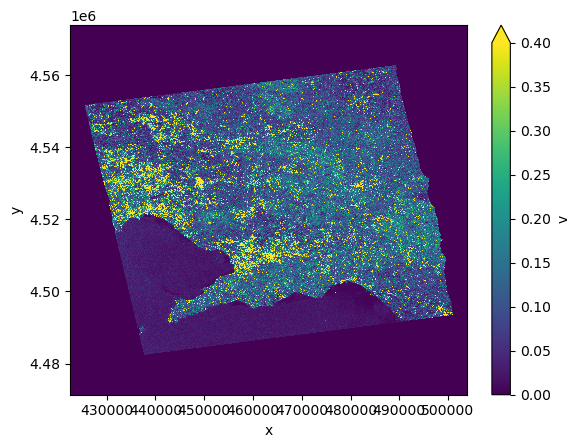

In [23]:
np.real(g_ml).plot(vmin=0, vmax=0.4)